# PayGuard — Final Model Comparison (All 5 Models)

Loads the saved results from all five model notebooks and builds the single grand comparison table — the centerpiece table for your report and viva.

Models: Logistic Regression, Random Forest, XGBoost (supervised) and Isolation Forest, One-Class SVM (unsupervised).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

model_files = {
    "Logistic Regression": "../models/logistic_regression_results.csv",
    "Random Forest": "../models/random_forest_results.csv",
    "XGBoost": "../models/xgboost_results.csv",
    "Isolation Forest": "../models/isolation_forest_results.csv",
    "One-Class SVM": "../models/one_class_svm_results.csv",
}

all_results = []
for model_name, path in model_files.items():
    df = pd.read_csv(path)
    all_results.append(df)

all_results_df = pd.concat(all_results, ignore_index=True)
print(f"Loaded results for {all_results_df['model'].nunique()} models, "
      f"{len(all_results_df)} total (model, preprocessing variant) rows.")
all_results_df

Loaded results for 5 models, 15 total (model, preprocessing variant) rows.


,model,variant,precision,recall,f1,roc_auc,true_positives,false_positives,true_negatives,false_negatives
0,Logistic Regression,Class-Weighted,0.0399,0.8222,0.0761,0.9624,37,890,15065,8
1,Logistic Regression,SMOTE,0.0382,0.7778,0.0728,0.9480,35,881,15074,10
2,Logistic Regression,Undersampling,0.0313,0.8667,0.0604,0.9497,39,1208,14747,6
3,Random Forest,Class-Weighted,0.7619,0.7111,0.7356,0.9699,32,10,15945,13
4,Random Forest,SMOTE,0.1667,0.7333,0.2716,0.9683,33,165,15790,12
5,Random Forest,Undersampling,0.0348,0.8889,0.0669,0.9676,40,1111,14844,5
6,XGBoost,SMOTE,0.7200,0.8000,0.7579,0.9843,36,14,15941,9
7,XGBoost,Class-Weighted,0.7292,0.7778,0.7527,0.9723,35,13,15942,10
8,XGBoost,Undersampling,0.0289,0.8889,0.0559,0.9539,40,1345,14610,5
9,Isolation Forest,Wider Net (2x Rate),0.0400,0.0667,0.0500,0.8055,3,72,15883,42


## Table 1: Every variant of every model (full detail, for the appendix)

In [2]:
all_results_df_sorted = all_results_df.sort_values("f1", ascending=False).reset_index(drop=True)
all_results_df_sorted.to_csv("../models/all_models_all_variants.csv", index=False)
all_results_df_sorted

,model,variant,precision,recall,f1,roc_auc,true_positives,false_positives,true_negatives,false_negatives
0,XGBoost,SMOTE,0.7200,0.8000,0.7579,0.9843,36,14,15941,9
1,XGBoost,Class-Weighted,0.7292,0.7778,0.7527,0.9723,35,13,15942,10
2,Random Forest,Class-Weighted,0.7619,0.7111,0.7356,0.9699,32,10,15945,13
3,Random Forest,SMOTE,0.1667,0.7333,0.2716,0.9683,33,165,15790,12
4,One-Class SVM,Wider Net (2x Rate),0.0491,0.1778,0.0769,0.6572,8,155,15800,37
5,One-Class SVM,Calibrated to True Rate,0.0488,0.1778,0.0766,0.6561,8,156,15799,37
6,Logistic Regression,Class-Weighted,0.0399,0.8222,0.0761,0.9624,37,890,15065,8
7,Logistic Regression,SMOTE,0.0382,0.7778,0.0728,0.9480,35,881,15074,10
8,Random Forest,Undersampling,0.0348,0.8889,0.0669,0.9676,40,1111,14844,5
9,Logistic Regression,Undersampling,0.0313,0.8667,0.0604,0.9497,39,1208,14747,6


## Table 2: Best variant per model (the headline comparison table)

This is the table to put front-and-center in your report — one row per model, its best preprocessing/tuning choice, and how they stack up.

In [3]:
best_per_model = (
    all_results_df.sort_values("f1", ascending=False)
    .groupby("model", sort=False)
    .first()
    .reset_index()
)

# order: supervised models first (by F1), then unsupervised (by ROC-AUC, since their F1
# is threshold-dependent and not directly comparable to the supervised models' F1)
model_order = ["Logistic Regression", "Random Forest", "XGBoost", "Isolation Forest", "One-Class SVM"]
best_per_model["model"] = pd.Categorical(best_per_model["model"], categories=model_order, ordered=True)
best_per_model = best_per_model.sort_values("model").reset_index(drop=True)

best_per_model.to_csv("../models/best_model_per_type.csv", index=False)
best_per_model[["model", "variant", "precision", "recall", "f1", "roc_auc",
                "true_positives", "false_positives", "false_negatives"]]

,model,variant,precision,recall,f1,roc_auc,true_positives,false_positives,false_negatives
0,Logistic Regression,Class-Weighted,0.0399,0.8222,0.0761,0.9624,37,890,8
1,Random Forest,Class-Weighted,0.7619,0.7111,0.7356,0.9699,32,10,13
2,XGBoost,SMOTE,0.7200,0.8000,0.7579,0.9843,36,14,9
3,Isolation Forest,Wider Net (2x Rate),0.0400,0.0667,0.0500,0.8055,3,72,42
4,One-Class SVM,Wider Net (2x Rate),0.0491,0.1778,0.0769,0.6572,8,155,37


## Chart 1: Precision vs. Recall vs. F1 across all five models

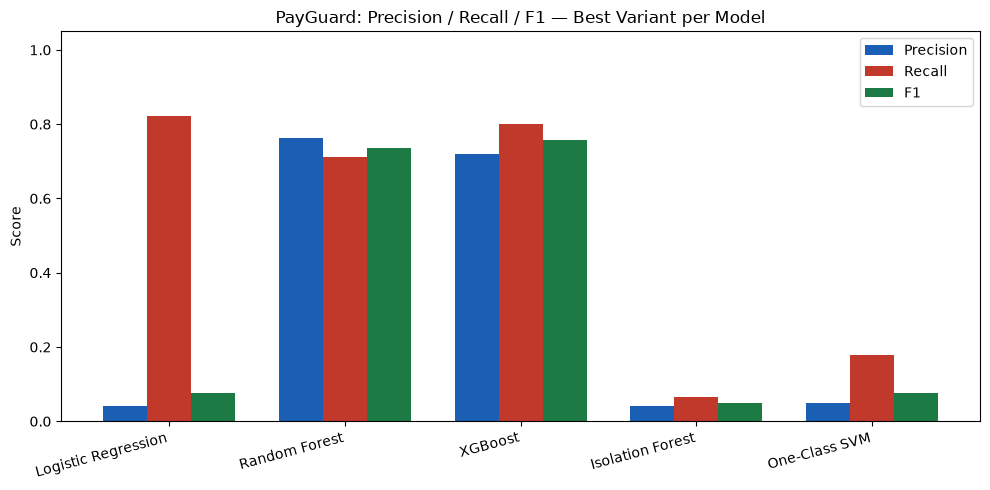

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(best_per_model))
width = 0.25

ax.bar([i - width for i in x], best_per_model["precision"], width, label="Precision", color="#1A5FB4")
ax.bar(x, best_per_model["recall"], width, label="Recall", color="#C0392B")
ax.bar([i + width for i in x], best_per_model["f1"], width, label="F1", color="#1C7A45")

ax.set_xticks(list(x))
ax.set_xticklabels(best_per_model["model"], rotation=15, ha="right")
ax.set_ylabel("Score")
ax.set_title("PayGuard: Precision / Recall / F1 — Best Variant per Model")
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("../models/comparison_chart_prf1.png", dpi=150)
plt.show()

## Chart 2: ROC-AUC across all five models

The fairest single number to compare supervised and unsupervised models side by side, since it doesn't depend on where the decision threshold was set.

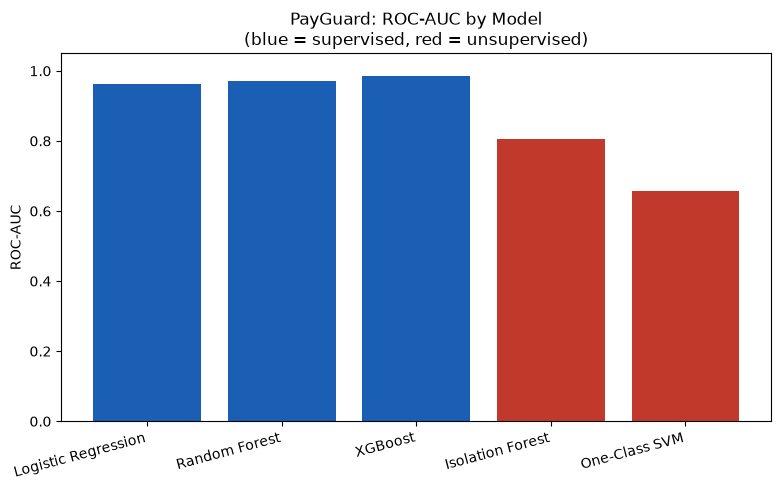

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#1A5FB4" if m in ["Logistic Regression", "Random Forest", "XGBoost"] else "#C0392B"
          for m in best_per_model["model"]]

ax.bar(best_per_model["model"].astype(str), best_per_model["roc_auc"], color=colors)
ax.set_ylabel("ROC-AUC")
ax.set_title("PayGuard: ROC-AUC by Model\n(blue = supervised, red = unsupervised)")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("../models/comparison_chart_rocauc.png", dpi=150)
plt.show()

## Pick the single model to carry forward into the app (SHAP + backend)

We need **one supervised model** going forward for SHAP explainability and the live API — unsupervised models stay in the report as the comparison/discussion point ("what if we had no labels"), but the deployed system scores transactions with the best-performing supervised model.

In [6]:
supervised_results = best_per_model[best_per_model["model"].isin(
    ["Logistic Regression", "Random Forest", "XGBoost"]
)].sort_values("f1", ascending=False)

champion = supervised_results.iloc[0]
print(f"Champion model for deployment: {champion['model']} ({champion['variant']})")
print(f"F1: {champion['f1']}  |  Precision: {champion['precision']}  |  Recall: {champion['recall']}  |  ROC-AUC: {champion['roc_auc']}")
print("\nThis is the model SHAP and the backend inference service will load going forward.")

Champion model for deployment: XGBoost (SMOTE)
F1: 0.7579  |  Precision: 0.72  |  Recall: 0.8  |  ROC-AUC: 0.9843

This is the model SHAP and the backend inference service will load going forward.


## Summary for your report

Fill in the actual numbers from the tables/charts above. Suggested narrative structure:

1. **Baseline (Logistic Regression):** high recall, very low precision — establishes that this problem needs more than a linear model.
2. **Random Forest:** a large precision improvement over the baseline, moderate recall — non-linear splits start to pay off.
3. **XGBoost:** the strongest supervised model — best balance of precision and recall, highest ROC-AUC among supervised models.
4. **Isolation Forest / One-Class SVM:** meaningfully lower ROC-AUC than the supervised models — quantifies the real cost of not having fraud labels, which directly supports the project's motivation for comparing both paradigms.
5. **Champion model:** state which model + preprocessing variant was carried forward into the SHAP + backend pipeline, and why (best F1 among supervised models — the most usable real-world balance of catching fraud vs. not overwhelming analysts with false alarms).

## Next: `06_shap_explainability.ipynb`

Wrap the champion model with a SHAP explainer and build the inference function that returns a risk score plus per-feature contributions — this is what the backend API will call.